# Entrenamiento, Evaluación y Selección del Modelo FAQ - UPQ

Este notebook implementa el flujo completo de aprendizaje supervisado para el **Chatbot de Preguntas Frecuentes (FAQ) de la Universidad Politécnica de Querétaro (UPQ)**:

1. **Carga y exploración del corpus** (`data/corpus_upq.csv`) con las columnas `texto`, `intencion` y `respuesta_oficial`.
2. **Preprocesamiento y normalización de texto** utilizando `limpiar_texto` del módulo `src/preprocess.py`.
3. **Partición estratificada 80/20** (`train_test_split` con `stratify=y` y `random_state=42`).
4. **Validación cruzada estratificada de 5 pliegues** (`StratifiedKFold(n_splits=5, shuffle=True, random_state=42)`) sobre el conjunto de entrenamiento, encapsulando `TfidfVectorizer` + clasificador en un `Pipeline` para que el vectorizador se ajuste de forma independiente en cada pliegue.
5. **Extracción de características con TF-IDF** ajustada **únicamente sobre el conjunto de entrenamiento** (`fit_transform` en train, `transform` en test) para evitar fuga de datos (*data leakage*).
6. **Entrenamiento y evaluación comparativa** de tres clasificadores supervisados:
   - `LogisticRegression`
   - `CalibratedClassifierCV(LinearSVC)`
   - `MultinomialNB`
7. **Visualización de matrices de confusión y tabla comparativa de F1-score macro** (prueba y validación cruzada).
8. **Exportación por separado** del vectorizador (`models/vectorizador.pkl`) y del modelo ganador (`models/modelo.pkl`) mediante `joblib.dump`.

> **Alcance de esta versión (Fase 3 del cronograma):** split 80/20 estratificado, TF-IDF ajustado solo en train, CV 5-fold y comparativa de los 3 modelos.
> La exportación de artefactos (`models/*.pkl`, `reports/metrics.json` y matrices PNG en `reports/`) pertenece a la **Fase 4** y está desactivada mediante la bandera `EXPORTAR_ARTEFACTOS = False`, por lo que ejecutar este notebook **no sobrescribe** ningún archivo versionado.

## 1. Importación de librerías y configuración de rutas

In [1]:
import json
import platform
import sys
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
from sklearn.calibration import CalibratedClassifierCV
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    make_scorer,
    precision_score,
    recall_score,
)
from sklearn.model_selection import StratifiedKFold, cross_validate, train_test_split
from sklearn.naive_bayes import MultinomialNB
from sklearn.pipeline import Pipeline
from sklearn.svm import LinearSVC

# Configurar la raíz del proyecto para importar src.preprocess
BASE_DIR = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
if str(BASE_DIR) not in sys.path:
    sys.path.insert(0, str(BASE_DIR))

from src.preprocess import limpiar_texto

DATA_PATH = BASE_DIR / "data" / "corpus_upq.csv"
MODELS_DIR = BASE_DIR / "models"
REPORTS_DIR = BASE_DIR / "reports"
VECTORIZER_OUTPUT_PATH = MODELS_DIR / "vectorizador.pkl"
MODEL_OUTPUT_PATH = MODELS_DIR / "modelo.pkl"
METRICS_OUTPUT_PATH = REPORTS_DIR / "metrics.json"

# Semilla única del proyecto (docs/CONTRATOS.md, sección 4)
RANDOM_STATE = 42

# Fase 3: False -> no se escriben models/*.pkl, reports/metrics.json ni PNG en reports/.
# La exportación definitiva corresponde a la Fase 4 del cronograma (cambiar a True en esa fase).
EXPORTAR_ARTEFACTOS = False

MODELS_DIR.mkdir(parents=True, exist_ok=True)
REPORTS_DIR.mkdir(parents=True, exist_ok=True)

print(f"Directorio base del proyecto: {BASE_DIR}")
print(f"Python {platform.python_version()} | scikit-learn {sklearn.__version__} | pandas {pd.__version__} | numpy {np.__version__}")
print(f"EXPORTAR_ARTEFACTOS = {EXPORTAR_ARTEFACTOS}")

Directorio base del proyecto: C:\Users\Satanas\Documents\GitHub\IA\Tarea-especial2
Python 3.14.6 | scikit-learn 1.9.0 | pandas 3.0.3 | numpy 2.4.6
EXPORTAR_ARTEFACTOS = False


## 2. Carga y exploración del corpus (`data/corpus_upq.csv`)

Verificamos que el dataset cumpla con el contrato de datos (`texto,intencion,respuesta_oficial`) y revisamos la distribución de ejemplos por intención.

In [2]:
if not DATA_PATH.exists():
    raise FileNotFoundError(f"No se encontró el corpus en: {DATA_PATH}")

df = pd.read_csv(DATA_PATH, encoding="utf-8")

# Contrato de datos: exactamente 3 columnas en este orden (docs/CONTRATOS.md, sección 1)
columnas_contrato = ["texto", "intencion", "respuesta_oficial"]
if list(df.columns) != columnas_contrato:
    raise ValueError(f"El CSV debe contener exactamente las columnas {columnas_contrato}; se encontraron {list(df.columns)}")

registros_leidos = len(df)
df = df.dropna(subset=["texto", "intencion", "respuesta_oficial"]).copy()
print(f"Registros leídos: {registros_leidos} | descartados por nulos: {registros_leidos - len(df)}")
print(f"Total de registros cargados: {len(df)}")
print(f"Intenciones distintas: {df['intencion'].nunique()}")
print(f"Duplicados exactos en 'texto': {int(df['texto'].duplicated().sum())}")
print("\nDistribución por intención:")
print(df["intencion"].value_counts())
df.head()

Registros leídos: 375 | descartados por nulos: 0
Total de registros cargados: 375
Intenciones distintas: 15
Duplicados exactos en 'texto': 0

Distribución por intención:
intencion
admisiones                       25
oferta_educativa                 25
costos_pagos                     25
becas                            25
servicios_escolares              25
calendario_horarios              25
estancias_estadias               25
servicio_social                  25
titulacion                       25
idiomas_ingles                   25
ubicacion_transporte             25
actividades_extracurriculares    25
biblioteca_instalaciones         25
plataforma_sistemas              25
contacto_directorio              25
Name: count, dtype: int64


,texto,intencion,respuesta_oficial
0,¿Cuándo abre la convocatoria de admisión para ...,admisiones,El proceso de admisión de la Universidad Polit...
1,¿Cuáles son los requisitos para inscribirme co...,admisiones,El proceso de admisión de la Universidad Polit...
2,¿Cómo puedo sacar mi ficha para el examen de a...,admisiones,El proceso de admisión de la Universidad Polit...
3,¿Qué documentos necesito entregar para el proc...,admisiones,El proceso de admisión de la Universidad Polit...
4,¿Cuándo es la fecha del examen de admisión de ...,admisiones,El proceso de admisión de la Universidad Polit...


## 3. Limpieza y preprocesamiento de texto

Aplicamos la función `limpiar_texto` de `src/preprocess.py` para convertir a minúsculas, eliminar acentos/diacríticos, remover signos de puntuación y normalizar espacios.

In [3]:
df["texto_limpio"] = df["texto"].astype(str).apply(limpiar_texto)
X = df["texto_limpio"]
y = df["intencion"].astype(str)

print(f"Textos vacíos tras limpiar_texto: {int((X == '').sum())}")
print(f"Duplicados tras limpiar_texto: {int(X.duplicated().sum())}")
df[["texto", "texto_limpio", "intencion"]].head(10)

Textos vacíos tras limpiar_texto: 0
Duplicados tras limpiar_texto: 0


,texto,texto_limpio,intencion
0,¿Cuándo abre la convocatoria de admisión para ...,cuando abre la convocatoria de admision para n...,admisiones
1,¿Cuáles son los requisitos para inscribirme co...,cuales son los requisitos para inscribirme com...,admisiones
2,¿Cómo puedo sacar mi ficha para el examen de a...,como puedo sacar mi ficha para el examen de ad...,admisiones
3,¿Qué documentos necesito entregar para el proc...,que documentos necesito entregar para el proce...,admisiones
4,¿Cuándo es la fecha del examen de admisión de ...,cuando es la fecha del examen de admision de l...,admisiones
5,¿Dónde consulto la convocatoria vigente para a...,donde consulto la convocatoria vigente para as...,admisiones
6,¿Cuál es el proceso paso a paso para entrar a ...,cual es el proceso paso a paso para entrar a e...,admisiones
7,¿Dónde y cuándo se publican los resultados del...,donde y cuando se publican los resultados del ...,admisiones
8,¿Hasta qué fecha límite tengo para registrarme...,hasta que fecha limite tengo para registrarme ...,admisiones
9,¿Se requiere promedio mínimo de preparatoria p...,se requiere promedio minimo de preparatoria pa...,admisiones


## 4. División Estratificada 80/20 y Vectorización TF-IDF

Dividimos el corpus en **80% entrenamiento** y **20% prueba** conservando la proporción de cada clase (`stratify=y`).

Posteriormente ajustamos el `TfidfVectorizer(ngram_range=(1, 2))` **exclusivamente sobre `X_train`** y transformamos `X_test` con el vocabulario aprendido.

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    stratify=y,
    random_state=RANDOM_STATE,
)

vectorizador = TfidfVectorizer(ngram_range=(1, 2))
X_train_tfidf = vectorizador.fit_transform(X_train)
X_test_tfidf = vectorizador.transform(X_test)

print(f"Tamaño de entrenamiento: {X_train_tfidf.shape[0]} muestras | Vocabulario TF-IDF: {X_train_tfidf.shape[1]} términos")
print(f"Tamaño de prueba:        {X_test_tfidf.shape[0]} muestras")
print(f"Índices compartidos entre train y test: {len(set(X_train.index) & set(X_test.index))}")

# Comprobación de la estratificación: cada intención conserva su proporción en ambos conjuntos
distribucion_split = pd.DataFrame({
    "train": y_train.value_counts().sort_index(),
    "test": y_test.value_counts().sort_index(),
})
distribucion_split["total"] = distribucion_split["train"] + distribucion_split["test"]
distribucion_split["%_test"] = (distribucion_split["test"] / distribucion_split["total"] * 100).round(1)
distribucion_split

Tamaño de entrenamiento: 300 muestras | Vocabulario TF-IDF: 2896 términos
Tamaño de prueba:        75 muestras
Índices compartidos entre train y test: 0


,train,test,total,%_test
intencion,,,,
actividades_extracurriculares,20,5,25,20.0
admisiones,20,5,25,20.0
becas,20,5,25,20.0
biblioteca_instalaciones,20,5,25,20.0
calendario_horarios,20,5,25,20.0
contacto_directorio,20,5,25,20.0
costos_pagos,20,5,25,20.0
estancias_estadias,20,5,25,20.0
idiomas_ingles,20,5,25,20.0


## 5. Definición de los modelos candidatos

Los tres clasificadores y sus hiperparámetros son exactamente los establecidos en `docs/CONTRATOS.md` (sección 4). Se definen mediante una función que devuelve **instancias nuevas sin entrenar**, para que la validación cruzada y el entrenamiento final no compartan estado.

In [5]:
def crear_clasificadores() -> dict:
    """Devuelve instancias nuevas (sin entrenar) de los 3 modelos del contrato."""
    return {
        "logistic_regression": LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
        "linear_svc_calibrated": CalibratedClassifierCV(LinearSVC(random_state=RANDOM_STATE), cv=3),
        "multinomial_nb": MultinomialNB(),
    }

for nombre, clf in crear_clasificadores().items():
    print(f"{nombre:<24} -> {clf}")

logistic_regression      -> LogisticRegression(max_iter=1000, random_state=42)
linear_svc_calibrated    -> CalibratedClassifierCV(cv=3, estimator=LinearSVC(random_state=42))
multinomial_nb           -> MultinomialNB()


## 6. Validación Cruzada Estratificada (5 pliegues) con `Pipeline`

La validación cruzada se realiza **solo sobre el conjunto de entrenamiento** (`X_train`, `y_train`); el 20% de prueba no interviene.

Cada modelo se encapsula en un `Pipeline(TfidfVectorizer(ngram_range=(1, 2)) → clasificador)`. Así, en cada uno de los 5 pliegues el `TfidfVectorizer` aprende vocabulario e IDF **únicamente** con los 4/5 de entrenamiento del pliegue y solo transforma el pliegue de validación, evitando *data leakage* dentro de la validación cruzada.

`limpiar_texto` se aplicó antes del split porque es una transformación determinista fila por fila (no aprende parámetros del conjunto), por lo que no introduce fuga de información.

Métricas registradas: `accuracy`, `precision_macro`, `recall_macro` y `f1_macro` (métrica principal del contrato), en validación y en entrenamiento de cada pliegue.

In [6]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

metricas_cv = {
    "accuracy": "accuracy",
    "precision_macro": make_scorer(precision_score, average="macro", zero_division=0),
    "recall_macro": make_scorer(recall_score, average="macro", zero_division=0),
    "f1_macro": make_scorer(f1_score, average="macro", zero_division=0),
}

resultados_cv = {}
f1_por_pliegue = {}

for nombre, clf in crear_clasificadores().items():
    pipeline = Pipeline([
        ("tfidf", TfidfVectorizer(ngram_range=(1, 2))),
        ("clf", clf),
    ])
    puntajes = cross_validate(
        pipeline,
        X_train,
        y_train,
        cv=cv,
        scoring=metricas_cv,
        return_train_score=True,
        n_jobs=1,
    )
    resultados_cv[nombre] = {
        f"cv_{metrica}_{estadistico}": round(float(funcion(puntajes[f"test_{metrica}"])), 4)
        for metrica in metricas_cv
        for estadistico, funcion in (("mean", np.mean), ("std", np.std))
    }
    resultados_cv[nombre]["cv_train_f1_macro_mean"] = round(float(np.mean(puntajes["train_f1_macro"])), 4)
    f1_por_pliegue[nombre] = np.round(puntajes["test_f1_macro"], 4)

tabla_cv = pd.DataFrame(resultados_cv).T.sort_values(by="cv_f1_macro_mean", ascending=False)

print("F1-score macro por pliegue (validación):")
display(pd.DataFrame(f1_por_pliegue, index=[f"fold_{i}" for i in range(1, 6)]).T)

print("\nResumen de validación cruzada (media y desviación estándar de los 5 pliegues):")
tabla_cv

F1-score macro por pliegue (validación):


,fold_1,fold_2,fold_3,fold_4,fold_5
logistic_regression,0.5693,0.5626,0.5894,0.7405,0.5273
linear_svc_calibrated,0.5940,0.5603,0.5876,0.6803,0.5141
multinomial_nb,0.5524,0.5322,0.5220,0.6746,0.4358



Resumen de validación cruzada (media y desviación estándar de los 5 pliegues):


,cv_accuracy_mean,cv_accuracy_std,cv_precision_macro_mean,cv_precision_macro_std,cv_recall_macro_mean,cv_recall_macro_std,cv_f1_macro_mean,cv_f1_macro_std,cv_train_f1_macro_mean
logistic_regression,0.6067,0.0764,0.6441,0.0769,0.6067,0.0764,0.5978,0.0741,0.9958
linear_svc_calibrated,0.5967,0.0600,0.6354,0.0609,0.5967,0.0600,0.5873,0.0544,1.0000
multinomial_nb,0.5567,0.0807,0.5975,0.0762,0.5567,0.0807,0.5434,0.0767,0.9975


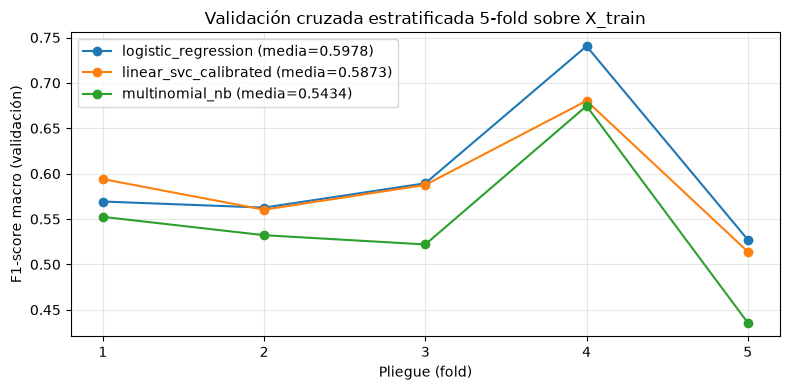

In [7]:
# Comparación visual de F1 macro por pliegue (validación cruzada)
fig, ax = plt.subplots(figsize=(8, 4))
for nombre, valores in f1_por_pliegue.items():
    ax.plot(range(1, 6), valores, marker="o", label=f"{nombre} (media={np.mean(valores):.4f})")
ax.set_xticks(range(1, 6))
ax.set_xlabel("Pliegue (fold)")
ax.set_ylabel("F1-score macro (validación)")
ax.set_title("Validación cruzada estratificada 5-fold sobre X_train")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 7. Entrenamiento final, Evaluación en Prueba y Matrices de Confusión

Entrenamos tres clasificadores con soporte para probabilidades (`predict_proba`) sobre el 80% de entrenamiento ya vectorizado (`X_train_tfidf`) y los evaluamos sobre el 20% de prueba (`X_test_tfidf`), que el vectorizador nunca vio durante su ajuste:
- **LogisticRegression**: clasificador lineal regularizado con salida probabilística directa.
- **LinearSVC calibrado (`CalibratedClassifierCV`)**: máquina de vectores de soporte lineal con calibración de probabilidades mediante validación cruzada.
- **MultinomialNB**: clasificador Naive Bayes multinomial clásico para conteos y pesos TF-IDF.

Calculamos `Accuracy`, `Precision macro`, `Recall macro`, `F1-score macro` en prueba (y accuracy/F1 macro en entrenamiento para detectar sobreajuste) y graficamos la matriz de confusión de cada modelo.

Modelo: logistic_regression
----------------------------------------------------------------------
                               precision    recall  f1-score   support

actividades_extracurriculares       0.50      0.60      0.55         5
                   admisiones       0.67      0.80      0.73         5
                        becas       1.00      0.80      0.89         5
     biblioteca_instalaciones       1.00      0.60      0.75         5
          calendario_horarios       0.50      0.60      0.55         5
          contacto_directorio       0.50      0.60      0.55         5
                 costos_pagos       1.00      0.60      0.75         5
           estancias_estadias       1.00      0.60      0.75         5
               idiomas_ingles       0.80      0.80      0.80         5
             oferta_educativa       0.43      0.60      0.50         5
          plataforma_sistemas       0.60      0.60      0.60         5
              servicio_social       1.00      0.

Modelo: linear_svc_calibrated
----------------------------------------------------------------------
                               precision    recall  f1-score   support

actividades_extracurriculares       0.50      0.60      0.55         5
                   admisiones       0.67      0.80      0.73         5
                        becas       1.00      0.80      0.89         5
     biblioteca_instalaciones       0.67      0.80      0.73         5
          calendario_horarios       0.50      0.60      0.55         5
          contacto_directorio       0.50      0.40      0.44         5
                 costos_pagos       1.00      0.60      0.75         5
           estancias_estadias       1.00      0.60      0.75         5
               idiomas_ingles       0.80      0.80      0.80         5
             oferta_educativa       0.60      0.60      0.60         5
          plataforma_sistemas       0.60      0.60      0.60         5
              servicio_social       0.80      

Modelo: multinomial_nb
----------------------------------------------------------------------
                               precision    recall  f1-score   support

actividades_extracurriculares       0.50      0.60      0.55         5
                   admisiones       0.40      0.80      0.53         5
                        becas       0.75      0.60      0.67         5
     biblioteca_instalaciones       1.00      0.60      0.75         5
          calendario_horarios       0.75      0.60      0.67         5
          contacto_directorio       0.33      0.20      0.25         5
                 costos_pagos       1.00      0.60      0.75         5
           estancias_estadias       0.75      0.60      0.67         5
               idiomas_ingles       0.80      0.80      0.80         5
             oferta_educativa       0.43      0.60      0.50         5
          plataforma_sistemas       0.75      0.60      0.67         5
              servicio_social       0.57      0.80   

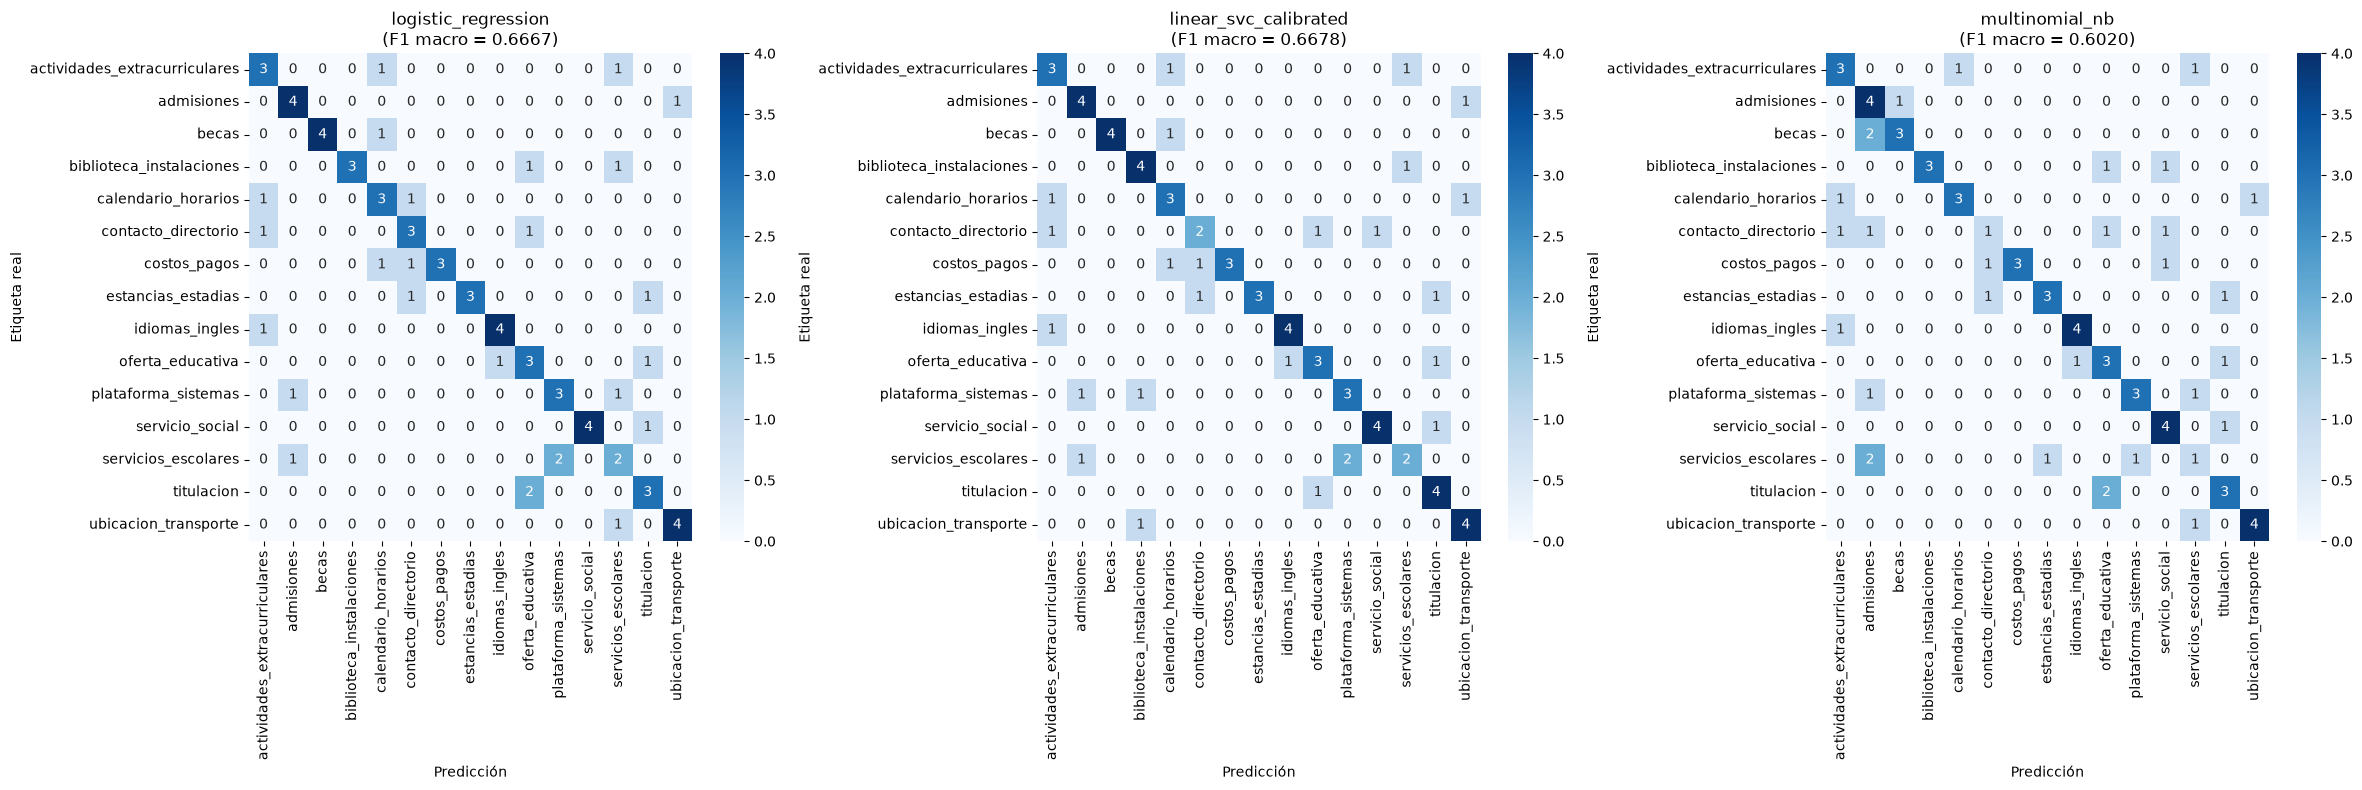

In [8]:
etiquetas = sorted(y.unique().tolist())

clasificadores = crear_clasificadores()

resultados = {}
modelos_entrenados = {}

fig, axes = plt.subplots(1, 3, figsize=(24, 8))

for ax, (nombre, clf) in zip(axes, clasificadores.items()):
    clf.fit(X_train_tfidf, y_train)
    y_pred = clf.predict(X_test_tfidf)
    y_pred_train = clf.predict(X_train_tfidf)
    accuracy_train = float(accuracy_score(y_train, y_pred_train))
    f1_macro_train = float(f1_score(y_train, y_pred_train, average="macro", zero_division=0))

    accuracy = float(accuracy_score(y_test, y_pred))
    precision_macro = float(precision_score(y_test, y_pred, average="macro", zero_division=0))
    recall_macro = float(recall_score(y_test, y_pred, average="macro", zero_division=0))
    f1_macro = float(f1_score(y_test, y_pred, average="macro", zero_division=0))

    print("=" * 70)
    print(f"Modelo: {nombre}")
    print("-" * 70)
    print(classification_report(y_test, y_pred, zero_division=0))
    print(f"F1-score macro (prueba): {f1_macro:.4f} | F1-score macro (entrenamiento): {f1_macro_train:.4f}\n")

    cm = confusion_matrix(y_test, y_pred, labels=etiquetas)
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=etiquetas,
        yticklabels=etiquetas,
        ax=ax,
    )
    ax.set_title(f"{nombre}\n(F1 macro = {f1_macro:.4f})")
    ax.set_xlabel("Predicción")
    ax.set_ylabel("Etiqueta real")
    ax.tick_params(axis="x", rotation=90)
    ax.tick_params(axis="y", rotation=0)

    # Guardar también cada matriz de confusión individual en reports/ (Fase 4: solo si EXPORTAR_ARTEFACTOS)
    ruta_cm = REPORTS_DIR / f"confusion_matrix_{nombre}.png"
    if EXPORTAR_ARTEFACTOS:
        fig_ind, ax_ind = plt.subplots(figsize=(7, 5))
        sns.heatmap(
            cm,
            annot=True,
            fmt="d",
            cmap="Blues",
            xticklabels=etiquetas,
            yticklabels=etiquetas,
            ax=ax_ind,
        )
        ax_ind.set_title(f"Matriz de Confusión - {nombre}")
        ax_ind.set_xlabel("Predicción")
        ax_ind.set_ylabel("Etiqueta real")
        plt.xticks(rotation=30, ha="right")
        plt.yticks(rotation=0)
        plt.tight_layout()
        fig_ind.savefig(ruta_cm, dpi=150)
        plt.close(fig_ind)

    resultados[nombre] = {
        "accuracy": round(accuracy, 4),
        "precision_macro": round(precision_macro, 4),
        "recall_macro": round(recall_macro, 4),
        "f1_macro": round(f1_macro, 4),
        "accuracy_train": round(accuracy_train, 4),
        "f1_macro_train": round(f1_macro_train, 4),
        "errores_test": int((y_pred != y_test.to_numpy()).sum()),
        "confusion_matrix_path": str(ruta_cm.relative_to(BASE_DIR)),
        "classification_report": classification_report(
            y_test, y_pred, output_dict=True, zero_division=0
        ),
    }
    modelos_entrenados[nombre] = clf

plt.tight_layout()
plt.show()

## 8. Tabla Comparativa Final y Selección del Mejor Modelo

Criterio de selección del contrato (`docs/CONTRATOS.md`, sección 4): **mayor `F1-score macro` en el conjunto de prueba (20%)**, respaldado por la validación cruzada estratificada de 5 pliegues. La tabla combina ambas fuentes y verifica si los dos rankings coinciden.

In [9]:
tabla_comparativa = pd.DataFrame(
    [
        {
            "modelo": nombre,
            "accuracy": datos["accuracy"],
            "precision_macro": datos["precision_macro"],
            "recall_macro": datos["recall_macro"],
            "f1_macro": datos["f1_macro"],
            "errores_test": f"{datos['errores_test']} / {len(y_test)}",
            "f1_macro_train": datos["f1_macro_train"],
            "cv_f1_macro_mean": resultados_cv[nombre]["cv_f1_macro_mean"],
            "cv_f1_macro_std": resultados_cv[nombre]["cv_f1_macro_std"],
        }
        for nombre, datos in resultados.items()
    ]
).sort_values(by=["f1_macro", "cv_f1_macro_mean"], ascending=False)

modelo_ganador = str(tabla_comparativa.iloc[0]["modelo"])
mejor_f1 = float(tabla_comparativa.iloc[0]["f1_macro"])
mejor_cv = str(tabla_cv.index[0])

print(f"Modelo ganador seleccionado: {modelo_ganador} (F1-score macro = {mejor_f1:.4f})")
print(f"Mejor modelo según validación cruzada (F1 macro medio): {mejor_cv} "
      f"({tabla_cv.loc[mejor_cv, 'cv_f1_macro_mean']:.4f} ± {tabla_cv.loc[mejor_cv, 'cv_f1_macro_std']:.4f})")
print("Ranking de prueba y de CV coinciden en el primer lugar:", modelo_ganador == mejor_cv)
tabla_comparativa.reset_index(drop=True)

Modelo ganador seleccionado: linear_svc_calibrated (F1-score macro = 0.6678)
Mejor modelo según validación cruzada (F1 macro medio): logistic_regression (0.5978 ± 0.0741)
Ranking de prueba y de CV coinciden en el primer lugar: False


,modelo,accuracy,precision_macro,recall_macro,f1_macro,errores_test,f1_macro_train,cv_f1_macro_mean,cv_f1_macro_std
0,linear_svc_calibrated,0.6667,0.6914,0.6667,0.6678,25 / 75,1.0000,0.5873,0.0544
1,logistic_regression,0.6533,0.7086,0.6533,0.6667,26 / 75,0.9933,0.5978,0.0741
2,multinomial_nb,0.6000,0.6389,0.6000,0.6020,30 / 75,0.9967,0.5434,0.0767


## 9. Justificación técnica de la selección (Fase 3)

> Los valores citados corresponden a la ejecución guardada de este notebook (`random_state=42`, corpus de 375 registros). Si cambia `data/corpus_upq.csv` o `src/preprocess.py`, esta sección debe revisarse tras volver a ejecutar.

**Resultados observados**

| Modelo | F1 macro prueba | Errores prueba | F1 macro CV (5-fold) | F1 macro entrenamiento |
| :--- | :---: | :---: | :---: | :---: |
| `CalibratedClassifierCV(LinearSVC)` | **0.6678** | 25 / 75 | 0.5873 ± 0.0544 | 1.0000 |
| `LogisticRegression` | 0.6667 | 26 / 75 | **0.5978 ± 0.0741** | 0.9933 |
| `MultinomialNB` | 0.6020 | 30 / 75 | 0.5434 ± 0.0767 | 0.9967 |

**Selección según el contrato.** El criterio de `docs/CONTRATOS.md` es el mayor F1 macro en prueba, por lo que el modelo seleccionado es **`CalibratedClassifierCV(LinearSVC)`**. Sin embargo, su ventaja sobre `LogisticRegression` es de solo 0.0011 (un error de diferencia sobre 75 muestras), y en validación cruzada el orden se invierte (0.5978 vs 0.5873), con una diferencia menor que la desviación estándar entre pliegues. **Ambos modelos lineales están técnicamente empatados**; la elección definitiva debe confirmarse en la Fase 4 junto con el análisis de errores y la calibración del umbral.

**Por qué los modelos lineales superan a `MultinomialNB`.** `MultinomialNB` es el último tanto en prueba como en los 5 pliegues de CV. Asume independencia condicional entre términos y está pensado para conteos; con pesos TF-IDF y muchas expresiones compartidas entre intenciones (por ejemplo, "cuánto cuesta", "dónde puedo", "requisitos para"), esa suposición lo hace confundir clases. `LogisticRegression` y `LinearSVC` son discriminativos: aprenden directamente un peso por término y por clase para separar intenciones, pueden restar importancia a los términos comunes y funcionan bien en espacios dispersos de alta dimensión (2,896 características TF-IDF frente a 300 muestras de entrenamiento). `LinearSVC` maximiza el margen entre clases y `CalibratedClassifierCV` le añade `predict_proba`, requerido por `app.py`.

**Brecha entre entrenamiento y validación.** Los tres modelos alcanzan F1 ≈ 0.99–1.00 en entrenamiento, pero ≈ 0.54–0.60 en CV y ≈ 0.60–0.67 en prueba. Esto indica sobreajuste por la poca cantidad de ejemplos (20 por intención en entrenamiento) y por traslapes semánticos entre intenciones del corpus, no fuga de datos: el vectorizador se ajusta solo con `X_train` y, en la CV, dentro de cada pliegue mediante `Pipeline`. El análisis detallado de errores corresponde a la Fase 4.

## 10. Exportación de Artefactos (`models/vectorizador.pkl` y `models/modelo.pkl`) — Fase 4

Exportamos por separado el vectorizador TF-IDF y el clasificador ganador usando `joblib.dump` para que la aplicación de Streamlit (`app.py`) pueda cargarlos directamente.

> En la Fase 3 esta celda **no escribe archivos** (`EXPORTAR_ARTEFACTOS = False`). La exportación definitiva, junto con el análisis de errores y la calibración del umbral OOD, se realizará en la Fase 4.

In [10]:
if EXPORTAR_ARTEFACTOS:
    joblib.dump(vectorizador, VECTORIZER_OUTPUT_PATH)
    joblib.dump(modelos_entrenados[modelo_ganador], MODEL_OUTPUT_PATH)

    resumen_metricas = {
        "winner": modelo_ganador,
        "winner_f1_macro": mejor_f1,
        "dataset_size": int(len(df)),
        "train_size": int(len(X_train)),
        "test_size": int(len(X_test)),
        "classes": etiquetas,
        "models": resultados,
        "cross_validation": resultados_cv,
    }
    with METRICS_OUTPUT_PATH.open("w", encoding="utf-8") as archivo:
        json.dump(resumen_metricas, archivo, ensure_ascii=False, indent=2)

    print(f"Vectorizador guardado en: {VECTORIZER_OUTPUT_PATH}")
    print(f"Modelo ganador guardado en: {MODEL_OUTPUT_PATH}")
    print(f"Reporte de métricas guardado en: {METRICS_OUTPUT_PATH}")
else:
    print("EXPORTAR_ARTEFACTOS = False -> Fase 3: no se escribieron models/*.pkl, reports/metrics.json ni PNG.")
    print("La exportación definitiva corresponde a la Fase 4 del cronograma.")

EXPORTAR_ARTEFACTOS = False -> Fase 3: no se escribieron models/*.pkl, reports/metrics.json ni PNG.
La exportación definitiva corresponde a la Fase 4 del cronograma.
